In [70]:
import pandas as pd
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

In [71]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cpu


In [72]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [73]:
df = pd.read_csv("beijing+pm2+5+data/PRSA_data_2010.1.1-2014.12.31.csv")

In [ ]:

print("Columns:")
print(df.columns.tolist())

Columns:
['No', 'year', 'month', 'day', 'hour', 'pm2.5', 'DEWP', 'TEMP', 'PRES', 'cbwd', 'Iws', 'Is', 'Ir']


In [ ]:

print("First five rows:")
print(df.head())

First five rows:
   No  year  month  day  hour  pm2.5  DEWP  TEMP    PRES cbwd    Iws  Is  Ir
0   1  2010      1    1     0    NaN   -21 -11.0  1021.0   NW   1.79   0   0
1   2  2010      1    1     1    NaN   -21 -12.0  1020.0   NW   4.92   0   0
2   3  2010      1    1     2    NaN   -21 -11.0  1019.0   NW   6.71   0   0
3   4  2010      1    1     3    NaN   -21 -14.0  1019.0   NW   9.84   0   0
4   5  2010      1    1     4    NaN   -20 -12.0  1018.0   NW  12.97   0   0


In [ ]:
print("\nDataset shape:")
print(df.shape)

print("\nStatistical summary:")
print(df.describe())

print("\nDataset information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nMissing-value percentage:")
print((df.isnull().mean() * 100).round(2))


Dataset shape:
(43824, 13)

Statistical summary:
                 No          year         month           day          hour  \
count  43824.000000  43824.000000  43824.000000  43824.000000  43824.000000   
mean   21912.500000   2012.000000      6.523549     15.727820     11.500000   
std    12651.043435      1.413842      3.448572      8.799425      6.922266   
min        1.000000   2010.000000      1.000000      1.000000      0.000000   
25%    10956.750000   2011.000000      4.000000      8.000000      5.750000   
50%    21912.500000   2012.000000      7.000000     16.000000     11.500000   
75%    32868.250000   2013.000000     10.000000     23.000000     17.250000   
max    43824.000000   2014.000000     12.000000     31.000000     23.000000   

              pm2.5          DEWP          TEMP          PRES           Iws  \
count  41757.000000  43824.000000  43824.000000  43824.000000  43824.000000   
mean      98.613215      1.817246     12.448521   1016.447654     23.889140   
s

In [77]:
print(df.isnull().sum())
print("Total missing:", df.isnull().sum().sum())

No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64
Total missing: 2067


In [ ]:
df = df.dropna(subset=["pm2.5"]).copy() 

In [ ]:
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("datetime").reset_index(drop=True) 

In [ ]:
from sklearn.model_selection import train_test_split

train, temp = train_test_split(df, test_size=0.30, shuffle=False)

val, test = train_test_split(temp, test_size=0.15, shuffle=False)

print(train.shape)
print(val.shape)
print(test.shape)

(29229, 14)
(10648, 14)
(1880, 14)


In [81]:
df.dtypes

No                   int64
year                 int64
month                int64
day                  int64
hour                 int64
pm2.5              float64
DEWP                 int64
TEMP               float64
PRES               float64
cbwd                object
Iws                float64
Is                   int64
Ir                   int64
datetime    datetime64[ns]
dtype: object

In [82]:
from sklearn.preprocessing import StandardScaler

features = ["pm2.5","DEWP","TEMP","PRES","Iws","Is","Ir"]
scaler = StandardScaler()

train[features] = scaler.fit_transform(train[features])
val[features] = scaler.transform(val[features])
test[features] = scaler.transform(test[features])

In [83]:
print((train["datetime"].diff().value_counts()).head())

datetime
0 days 01:00:00    29065
0 days 02:00:00       85
0 days 03:00:00       18
0 days 08:00:00        6
0 days 11:00:00        3
Name: count, dtype: int64


In [84]:
def create_sequences(data, seq_length=24):
    X = []
    y = []

    values = data[features].values
    target = data["pm2.5"].values

    for i in range(len(data) - seq_length):
        X.append(values[i:i+seq_length])
        y.append(target[i+seq_length])

    return np.array(X), np.array(y)

In [85]:
X_train, y_train = create_sequences(train)
X_val, y_val = create_sequences(val)
X_test, y_test = create_sequences(test)

print(X_train.shape)
print(y_train.shape)

(29205, 24, 7)
(29205,)


In [86]:
class AirQualityDataset(Dataset):
    def __init__(self,X,y):
        self.X = torch.tensor(X,dtype=torch.float32)
        self.y = torch.tensor(y,dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self,idx):
        return self.X[idx],self.y[idx]

In [87]:
train_dataset = AirQualityDataset(X_train,y_train)
val_dataset = AirQualityDataset(X_val,y_val)
test_dataset = AirQualityDataset(X_test,y_test)

In [88]:
train_loader = DataLoader(
    train_dataset,
    batch_size = 64,
    shuffle = True
)

val_loader = DataLoader(
    val_dataset,
    batch_size = 64,
    shuffle = False
)

test_loader = DataLoader(
    test_dataset,
    batch_size = 64,
    shuffle = False
)

In [93]:
for X_batch, y_batch in train_loader:
    print("X batch shape:", X_batch.shape)
    print("y batch shape:", y_batch.shape)
    break

X batch shape: torch.Size([64, 24, 7])
y batch shape: torch.Size([64])


In [94]:
class LSTMModel(nn.Module):
    def __init__(self, input_size=7, hidden_size=64):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, (hidden, cell) = self.lstm(x)

        output = output[:, -1, :]
        prediction = self.fc(output)

        return prediction.squeeze(1)

In [95]:
import torch
import torch.nn as nn

model = LSTMModel(input_size=7, hidden_size=64).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

best_val_loss = float("inf")
EPOCHS = 20

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    # Save the best checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_lstm.pth")

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )

Epoch [1/20], Train Loss: 0.1615, Val Loss: 0.0524
Epoch [2/20], Train Loss: 0.0719, Val Loss: 0.0486
Epoch [3/20], Train Loss: 0.0695, Val Loss: 0.0489
Epoch [4/20], Train Loss: 0.0686, Val Loss: 0.0525
Epoch [5/20], Train Loss: 0.0678, Val Loss: 0.0466
Epoch [6/20], Train Loss: 0.0668, Val Loss: 0.0466
Epoch [7/20], Train Loss: 0.0667, Val Loss: 0.0464
Epoch [8/20], Train Loss: 0.0658, Val Loss: 0.0489
Epoch [9/20], Train Loss: 0.0649, Val Loss: 0.0465
Epoch [10/20], Train Loss: 0.0638, Val Loss: 0.0486
Epoch [11/20], Train Loss: 0.0636, Val Loss: 0.0468
Epoch [12/20], Train Loss: 0.0633, Val Loss: 0.0465
Epoch [13/20], Train Loss: 0.0628, Val Loss: 0.0466
Epoch [14/20], Train Loss: 0.0624, Val Loss: 0.0462
Epoch [15/20], Train Loss: 0.0620, Val Loss: 0.0491
Epoch [16/20], Train Loss: 0.0621, Val Loss: 0.0478
Epoch [17/20], Train Loss: 0.0615, Val Loss: 0.0466
Epoch [18/20], Train Loss: 0.0613, Val Loss: 0.0467
Epoch [19/20], Train Loss: 0.0604, Val Loss: 0.0476
Epoch [20/20], Train 

In [ ]:

import numpy as np
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error

model.load_state_dict(
    torch.load("best_lstm.pth", map_location=device)
)
model.eval()

predictions = []
actuals = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        output = model(X_batch)

        predictions.extend(output.cpu().numpy())
        actuals.extend(y_batch.cpu().numpy())

mae = mean_absolute_error(actuals, predictions)
rmse = np.sqrt(mean_squared_error(actuals, predictions))

print("LSTM Test MAE:", mae)
print("LSTM Test RMSE:", rmse)


LSTM Test MAE: 0.1390284
LSTM Test RMSE: 0.23688756


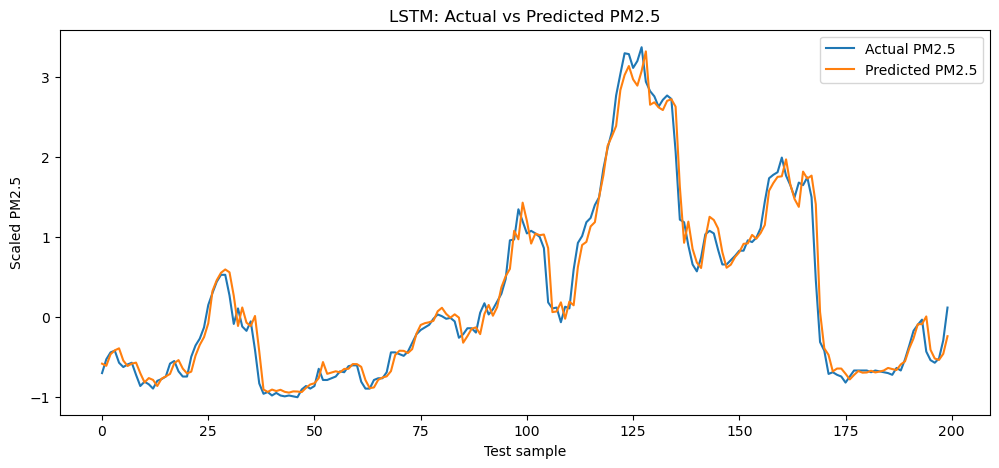

In [98]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(actuals[:200], label="Actual PM2.5")
plt.plot(predictions[:200], label="Predicted PM2.5")
plt.xlabel("Test sample")
plt.ylabel("Scaled PM2.5")
plt.title("LSTM: Actual vs Predicted PM2.5")
plt.legend()
plt.show()

In [ ]:
class GRUModel(nn.Module):
    def __init__(self, input_size=7, hidden_size=64):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, hidden = self.gru(x)

        output = output[:, -1, :]
        prediction = self.fc(output)

        return prediction.squeeze(1)

In [ ]:
import torch
import torch.nn as nn

model = GRUModel(input_size=7, hidden_size=64).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

best_val_loss = float("inf")
EPOCHS = 20

train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            val_loss += loss.item()

    val_loss /= len(val_loader)
    val_losses.append(val_loss)

    # Save the best checkpoint
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_gru.pth")

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}], "
        f"Train Loss: {train_loss:.4f}, "
        f"Val Loss: {val_loss:.4f}"
    )


Epoch [1/20], Train Loss: 0.1384, Val Loss: 0.0536
Epoch [2/20], Train Loss: 0.0710, Val Loss: 0.0489
Epoch [3/20], Train Loss: 0.0691, Val Loss: 0.0481
Epoch [4/20], Train Loss: 0.0687, Val Loss: 0.0483
Epoch [5/20], Train Loss: 0.0677, Val Loss: 0.0494
Epoch [6/20], Train Loss: 0.0671, Val Loss: 0.0481
Epoch [7/20], Train Loss: 0.0665, Val Loss: 0.0465
Epoch [8/20], Train Loss: 0.0656, Val Loss: 0.0472
Epoch [9/20], Train Loss: 0.0651, Val Loss: 0.0477
Epoch [10/20], Train Loss: 0.0646, Val Loss: 0.0478
Epoch [11/20], Train Loss: 0.0645, Val Loss: 0.0483
Epoch [12/20], Train Loss: 0.0636, Val Loss: 0.0462
Epoch [13/20], Train Loss: 0.0633, Val Loss: 0.0486
Epoch [14/20], Train Loss: 0.0638, Val Loss: 0.0470
Epoch [15/20], Train Loss: 0.0626, Val Loss: 0.0484
Epoch [16/20], Train Loss: 0.0624, Val Loss: 0.0478
Epoch [17/20], Train Loss: 0.0620, Val Loss: 0.0476
Epoch [18/20], Train Loss: 0.0619, Val Loss: 0.0464
Epoch [19/20], Train Loss: 0.0617, Val Loss: 0.0470
Epoch [20/20], Train 

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

actuals = []
predictions_list = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        predictions = model(X_batch)

        predictions_list.extend(predictions.cpu().numpy())
        actuals.extend(y_batch.numpy())

mae = mean_absolute_error(actuals, predictions_list)
rmse = np.sqrt(mean_squared_error(actuals, predictions_list))

print("GRU Test MAE:", mae)
print("GRU Test RMSE:", rmse)

GRU Test MAE: 0.13770138
GRU Test RMSE: 0.23599675


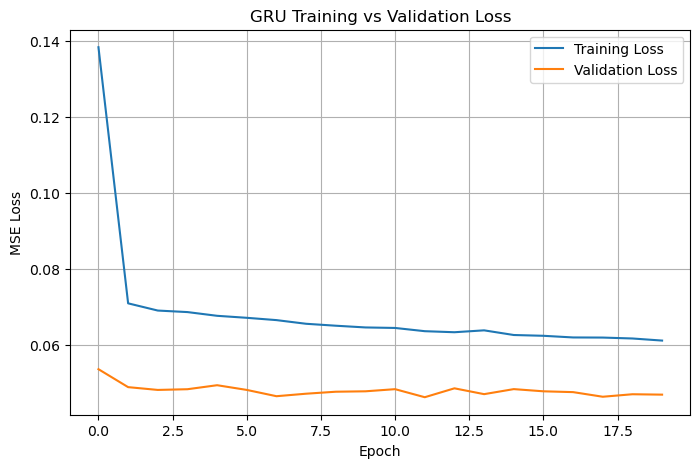

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("GRU Training vs Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

model.load_state_dict(
    torch.load("best_gru.pth", map_location=device)
)
model.eval()

actuals = []
predictions_list = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        X_batch = X_batch.to(device)

        predictions = model(X_batch)

        predictions_list.extend(predictions.cpu().numpy())
        actuals.extend(y_batch.numpy())


mae = mean_absolute_error(actuals, predictions_list)
rmse = np.sqrt(mean_squared_error(actuals, predictions_list))

print("GRU Test MAE:", mae)
print("GRU Test RMSE:", rmse)


GRU Test MAE: 0.13445845
GRU Test RMSE: 0.23676157


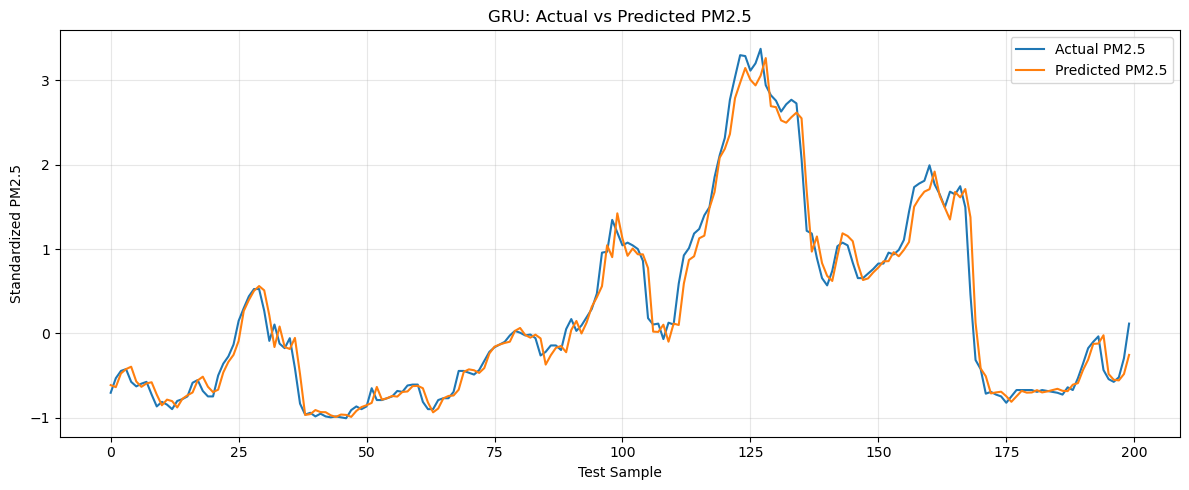

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(actuals[:200], label="Actual PM2.5")
plt.plot(predictions_list[:200], label="Predicted PM2.5")

plt.xlabel("Test Sample")
plt.ylabel("Standardized PM2.5")
plt.title("GRU: Actual vs Predicted PM2.5")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("gru_predictions.png", dpi=300)
plt.show()


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

pm_index = features.index("pm2.5")

pm_mean = scaler.mean_[pm_index]
pm_scale = scaler.scale_[pm_index]

actuals_original = np.array(actuals) * pm_scale + pm_mean

predictions_original = (
    np.array(predictions_list) * pm_scale + pm_mean
)

mae_original = mean_absolute_error(
    actuals_original, predictions_original
)

rmse_original = np.sqrt(
    mean_squared_error(actuals_original, predictions_original)
)

print(f"GRU Test MAE: {mae_original:.2f} µg/m³")
print(f"GRU Test RMSE: {rmse_original:.2f} µg/m³")


GRU Test MAE: 12.46 µg/m³
GRU Test RMSE: 21.93 µg/m³


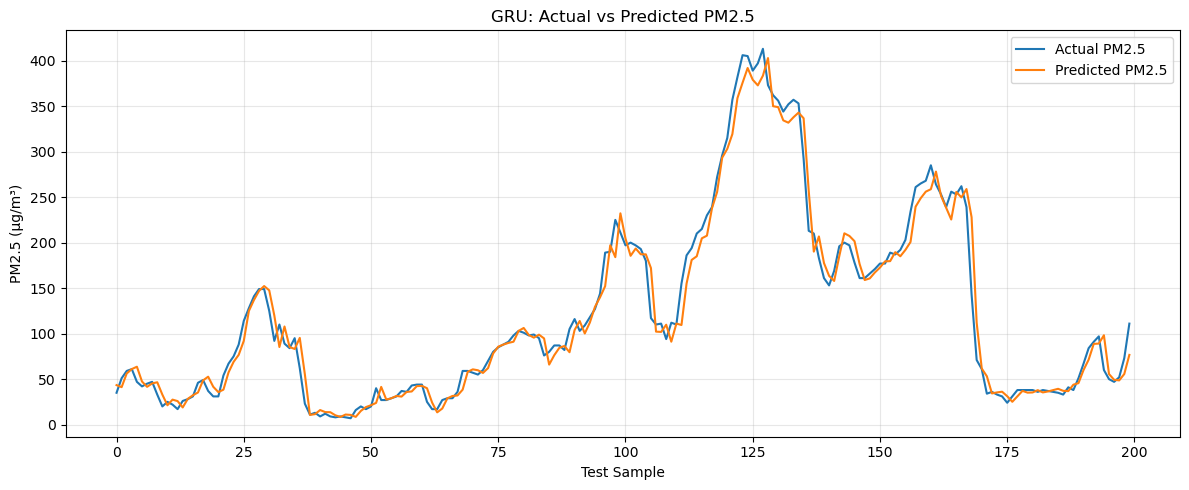

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    actuals_original[:200],
    label="Actual PM2.5"
)

plt.plot(
    predictions_original[:200],
    label="Predicted PM2.5"
)

plt.xlabel("Test Sample")
plt.ylabel("PM2.5 (µg/m³)")
plt.title("GRU: Actual vs Predicted PM2.5")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("gru_predictions_original.png", dpi=300)
plt.show()


Comparison table

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

lstm_mae = 0.13828863
lstm_rmse = 0.23958296


gru_mae = 0.13445845
gru_rmse = 0.23676157

results = pd.DataFrame({
    "Model": ["LSTM", "GRU"],
    "Test MAE": [lstm_mae, gru_mae],
    "Test RMSE": [lstm_rmse, gru_rmse]
})

print(results.round(4).to_string(index=False))


Model  Test MAE  Test RMSE
 LSTM    0.1383     0.2396
  GRU    0.1345     0.2368


Comparison graph

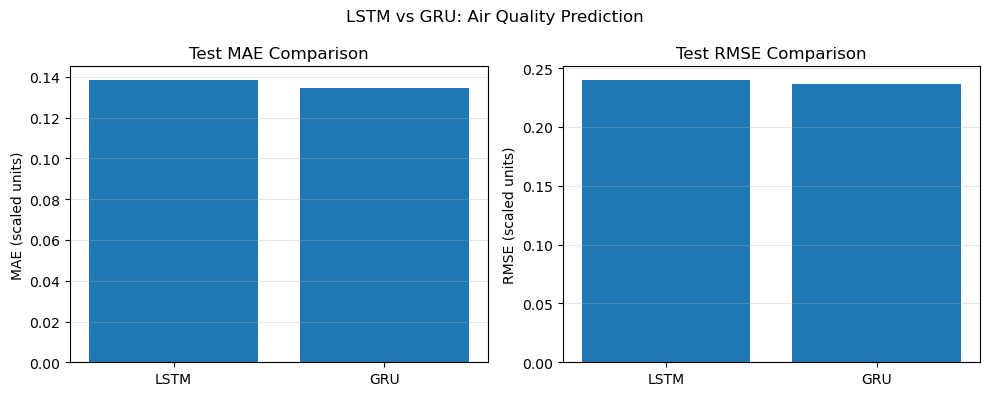

: 

In [ ]:
models = ["LSTM", "GRU"]

mae_values = [lstm_mae, gru_mae]
rmse_values = [lstm_rmse, gru_rmse]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# MAE comparison
axes[0].bar(models, mae_values)
axes[0].set_title("Test MAE Comparison")
axes[0].set_ylabel("MAE (scaled units)")

# RMSE comparison
axes[1].bar(models, rmse_values)
axes[1].set_title("Test RMSE Comparison")
axes[1].set_ylabel("RMSE (scaled units)")

for ax in axes:
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("LSTM vs GRU: Air Quality Prediction")
plt.tight_layout()

plt.savefig("lstm_gru_comparison.png", dpi=300)
plt.show()
